## Tokenization

In [1]:
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "tinystories.txt"

In [3]:
# UTF-8 encodes any Unicode character into 1-4 bytes (each 0-255),
# giving byte-level BPE universal coverage with just 256 base tokens.
for ch in ["h", "é", "अ", "😄"]:
    b = list(ch.encode("utf-8"))
    print(f"{ch} -> {len(b)} byte(s): {b}")

h -> 1 byte(s): [104]
é -> 2 byte(s): [195, 169]
अ -> 3 byte(s): [224, 164, 133]
😄 -> 4 byte(s): [240, 159, 152, 132]


## Byte-Pair Encoding (BPE) Primitives

In [4]:
text = DATA_PATH.read_text("utf-8")
tokens = list(text.encode("utf-8"))

print(repr(text[:10]))
print(tokens[:10])

'\nOnce upon'
[10, 79, 110, 99, 101, 32, 117, 112, 111, 110]


In [5]:
def count_pairs(tokens):
    return Counter(zip(tokens, tokens[1:]))

In [208]:
pair_counts = count_pairs(tokens)
pair_counts.most_common(10)

[((101, 32), 1818560),
 ((32, 116), 1494623),
 ((104, 101), 1488347),
 ((100, 32), 1385282),
 ((32, 97), 1116370),
 ((116, 104), 1021097),
 ((116, 32), 778755),
 ((46, 32), 777042),
 ((32, 115), 762590),
 ((97, 110), 759035)]

In [10]:
# Merge a pair of tokens
def merge(tokens, pair, new_token):
    """Replace all occurrences of pair with new_token in a new list."""
    new_tokens = []
    i = 0
    while i < len(tokens):
        if i < len(tokens) - 1 and tokens[i] == pair[0] and tokens[i + 1] == pair[1]:
            new_tokens.append(new_token)
            i += 2
        else:
            new_tokens.append(tokens[i])
            i += 1
    return new_tokens

### Baseline BPE Loop (2M Slice)
Each iteration passes through the token list twice (`count_pairs()` and `merge()`), so training thousands of merges on all 52M bytes would take hours.

In [211]:
# BPE training loop
sample_tokens = list(text[:2_000_000].encode("utf-8")) 

vocab_size = 500
merges = {}

 # Before training
original_length = len(sample_tokens)

pbar = tqdm(range(vocab_size - 256), desc="BPE Training", unit="merge")

for i in pbar:
    pair_counts = count_pairs(sample_tokens)
    pair = pair_counts.most_common(1)[0][0]

    new_token = i + 256
    sample_tokens = merge(sample_tokens, pair, new_token)
    merges[pair] = new_token

BPE Training: 100%|██████████| 244/244 [00:53<00:00,  4.56merge/s]


## Regex-Chunked BPE Training (Full 50 MB)

In [7]:
import regex as re
from collections import Counter

pattern = re.compile(r"'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+")

# Pre-tokenize each document and count unique chunks to avoid redundant BPE merges
word_counts = Counter()

for doc in text.split("<|endoftext|>"):
    word_counts.update(pattern.findall(doc))

print(f"Unique chunks: {len(word_counts):,}")
print(word_counts.most_common(10))

Unique chunks: 17,384
[('.', 982832), (',', 549695), (' the', 490401), (' and', 458279), (' a', 354354), (' to', 350527), ('\n', 307391), (' was', 249158), (' They', 123022), (' it', 120188)]


In [11]:
# Convert each unique word to [list_of_token_ids, frequency]
words = [[list(w.encode("utf-8")), freq] for w, freq in word_counts.items()]

vocab_size = 4095
merges = {}
compression_history = []
original_length = sum(len(t) * freq for t, freq in words)

pbar = tqdm(range(vocab_size - 256), desc="BPE Training", unit="merge")
for i in pbar:
    # 1. Count adjacent pairs weighted by word frequency
    pair_counts = Counter()
    for tokens, freq in words:
        for pair in zip(tokens, tokens[1:]):
            pair_counts[pair] += freq
    # 2. Pick top pair & record merge
    pair = max(pair_counts, key=pair_counts.get)
    new_token = 256 + i
    merges[pair] = new_token
    # 3. Merge inside each unique word (skipping words that can't match)
    for item in words:
        if len(item[0]) >= 2 and pair[0] in item[0]:
            item[0] = merge(item[0], pair, new_token)
    # 4. Log compression progress
    if i % 10 == 0:
        total_tokens = sum(len(t) * freq for t, freq in words)
        compression_history.append((new_token, total_tokens))
        pbar.set_postfix(ratio=f"{original_length / total_tokens:.2f}x")



BPE Training: 100%|██████████| 3839/3839 [01:15<00:00, 51.17merge/s, ratio=3.95x]


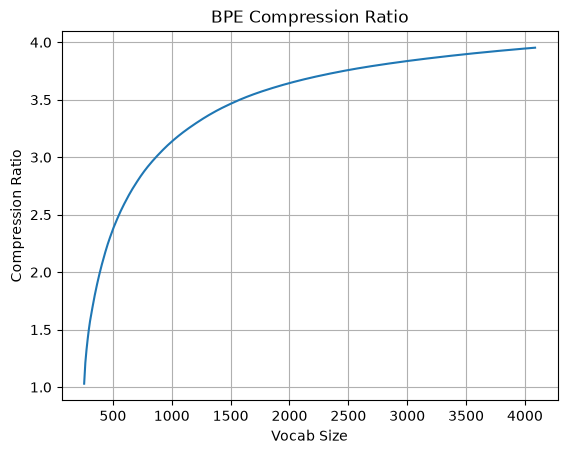

In [171]:
vocab_sizes, token_counts = zip(*compression_history)
ratios = [original_length / t for t in token_counts]

plt.plot(vocab_sizes, ratios)
plt.xlabel("Vocab Size")
plt.ylabel("Compression Ratio")
plt.title("BPE Compression Ratio")
plt.grid(True)
plt.show()

### Vocabulary & Special Tokens

In [13]:
vocab = {idx: bytes([idx]) for idx in range(256)}
for pair, token in merges.items():
    vocab[token] = vocab[pair[0]] + vocab[pair[1]]

special_tokens = {"<|endoftext|>": 4095}
for tok, idx in special_tokens.items():
    vocab[idx] = tok.encode("utf-8")

In [14]:
list(vocab.items())[-100:]

[(3996, b' Bessie'),
 (3997, b'Em'),
 (3998, b' rail'),
 (3999, b' shaking'),
 (4000, b' freezer'),
 (4001, b' chess'),
 (4002, b' shocked'),
 (4003, b' drawings'),
 (4004, b' stops'),
 (4005, b'ilot'),
 (4006, b' five'),
 (4007, b'bol'),
 (4008, b' drawer'),
 (4009, b' pirate'),
 (4010, b' holds'),
 (4011, b' Co'),
 (4012, b' gear'),
 (4013, b' check'),
 (4014, b' junk'),
 (4015, b' violin'),
 (4016, b' kay'),
 (4017, b' men'),
 (4018, b' often'),
 (4019, b'ric'),
 (4020, b' sailor'),
 (4021, b'xy'),
 (4022, b' available'),
 (4023, b' cord'),
 (4024, b' names'),
 (4025, b' may'),
 (4026, b'ymbol'),
 (4027, b' blin'),
 (4028, b' marble'),
 (4029, b'ature'),
 (4030, b' shrink'),
 (4031, b' pretending'),
 (4032, b'ination'),
 (4033, b' picking'),
 (4034, b'affe'),
 (4035, b'place'),
 (4036, b' marched'),
 (4037, b' against'),
 (4038, b' cardboard'),
 (4039, b' quiz'),
 (4040, b' Kiki'),
 (4041, b'ugged'),
 (4042, b' sne'),
 (4043, b' excitement'),
 (4044, b' neat'),
 (4045, b' stared'),


## Encoding, Decoding & Saving Tokens

In [15]:
def encode_chunk(chunk: str) -> list[int]:
    tokens = list(chunk.encode("utf-8"))
    while len(tokens) >= 2:
        # Apply the earliest-learned merge first (lowest ID in merges)
        pair = min(zip(tokens, tokens[1:]), key=lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break
        tokens = merge(tokens, pair, merges[pair])
    return tokens


def encode(text: str) -> list[int]:
    special_pattern = "(" + "|".join(re.escape(k) for k in special_tokens) + ")"
    parts = re.split(special_pattern, text)

    cache = {}
    ids = []
    for part in parts:
        if not part:
            continue
        if part in special_tokens:
            ids.append(special_tokens[part])
        else:
            for chunk in pattern.findall(part):
                if chunk not in cache:
                    cache[chunk] = encode_chunk(chunk)
                ids.extend(cache[chunk])
    return ids


def decode(ids: list[int]) -> str:
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")

In [16]:
# Encode the full dataset and save as uint16

encoded = encode(text)
np.array(encoded, dtype=np.uint16).tofile(PROJECT_ROOT / "data/tinystories_tokens.bin")

print(f"Saved {len(encoded):,} tokens ({len(encoded) * 2 / (1024**2):.2f} MB) to {PROJECT_ROOT / 'data/tinystories_tokens.bin'}")

Saved 13,114,638 tokens (25.01 MB) to /home/dhiran/projects/llm-from-scratch/data/tinystories_tokens.bin
